<a href="https://colab.research.google.com/github/esra03-1/icbhi-respiratory-sound-classification/blob/main/Solunum_Seslerinden_Patoloji_Siniflandirmasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Kaggle API ile veri setini Colab'a indirme
from google.colab import files
import os, glob
import pandas as pd

# kaggle.json dosyasını yükle
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Veri setini indir ve zipten çıkar
!kaggle datasets download -d vbookshelf/respiratory-sound-database
!unzip -q respiratory-sound-database.zip -d ./data

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/vbookshelf/respiratory-sound-database
License(s): unknown
100% 3.69G/3.69G [03:19<00:00, 19.8MB/s]



In [ ]:
# 2. Anotasyon dosyalarını okuyup 6.898 solunum döngüsünü tablo haline getirme
audio_dir = "./data/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files"
txt_files = sorted(glob.glob(os.path.join(audio_dir, "*.txt")))

records = []
for txt_path in txt_files:
    base_name = os.path.basename(txt_path).replace(".txt", "")
    wav_path = os.path.join(audio_dir, base_name + ".wav")
    if not os.path.exists(wav_path):
        continue

    # Dosya adından meta bilgileri ayıkla (Örn: 101_1b1_Al_sc_Meditron)
    parts = base_name.split("_")
    patient_id = parts[0]
    chest_loc = parts[2]
    equipment = parts[4]

    ann = pd.read_csv(txt_path, sep="\t", names=["start", "end", "crackles", "wheezes"])
    for idx, row in ann.iterrows():
        c, w = int(row["crackles"]), int(row["wheezes"])
        if c == 0 and w == 0:
            label = "Normal"
        elif c == 1 and w == 0:
            label = "Crackle"
        elif c == 0 and w == 1:
            label = "Wheeze"
        else:
            label = "Both"

        records.append({
            "patient_id": patient_id,
            "chest_loc": chest_loc,
            "equipment": equipment,
            "wav_path": wav_path,
            "start": row["start"],
            "end": row["end"],
            "duration": row["end"] - row["start"],
            "label": label
        })

df_cycles = pd.DataFrame(records)
print(f"Toplam solunum döngüsü: {len(df_cycles)}")
print(f"Toplam benzersiz hasta sayısı: {df_cycles['patient_id'].nunique()}")
print("\nSınıf Dağılımı:\n", df_cycles["label"].value_counts())

Toplam solunum döngüsü: 6898
Toplam benzersiz hasta sayısı: 126

Sınıf Dağılımı:
 label
Normal     3642
Crackle    1864
Wheeze      886
Both        506
Name: count, dtype: int64


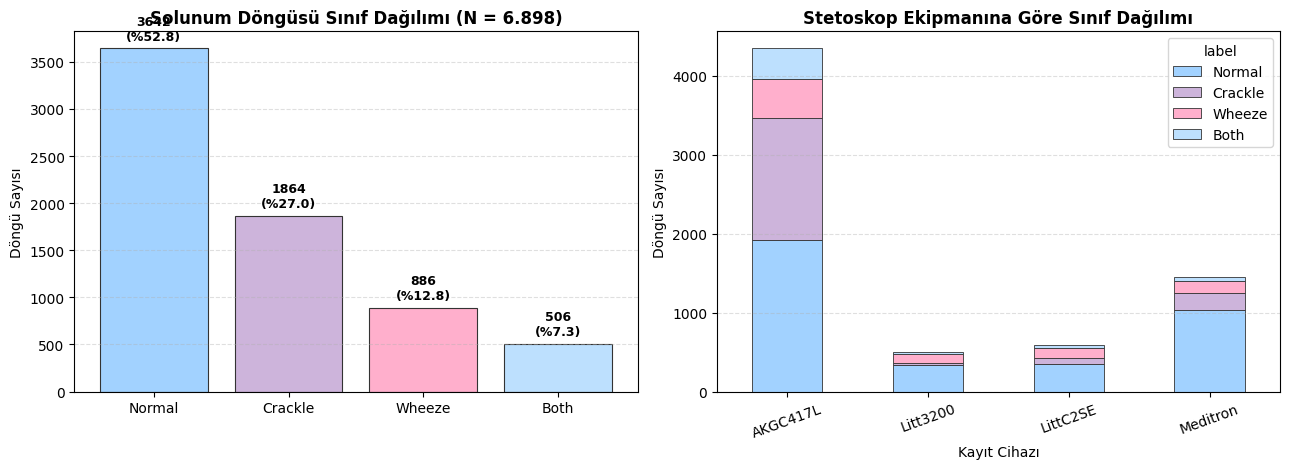

Süre Özeti -> Ortalama: 2.70 sn | Medyan: 2.54 sn | %90 Yüzdelik: 4.11 sn


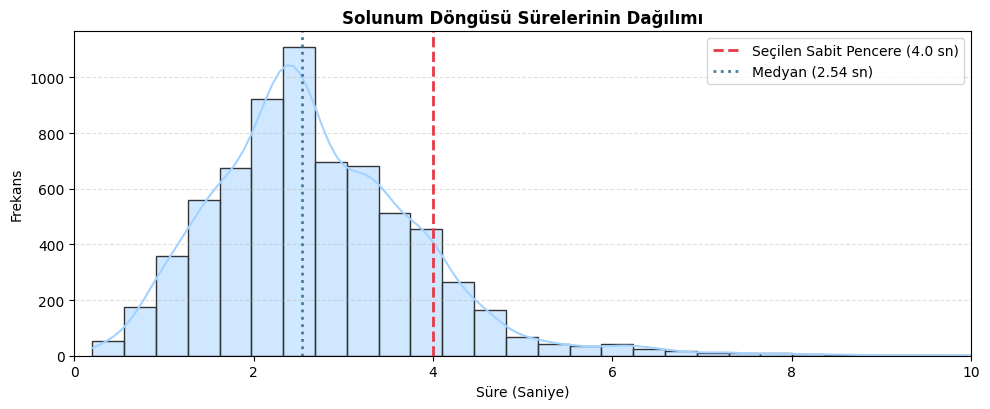

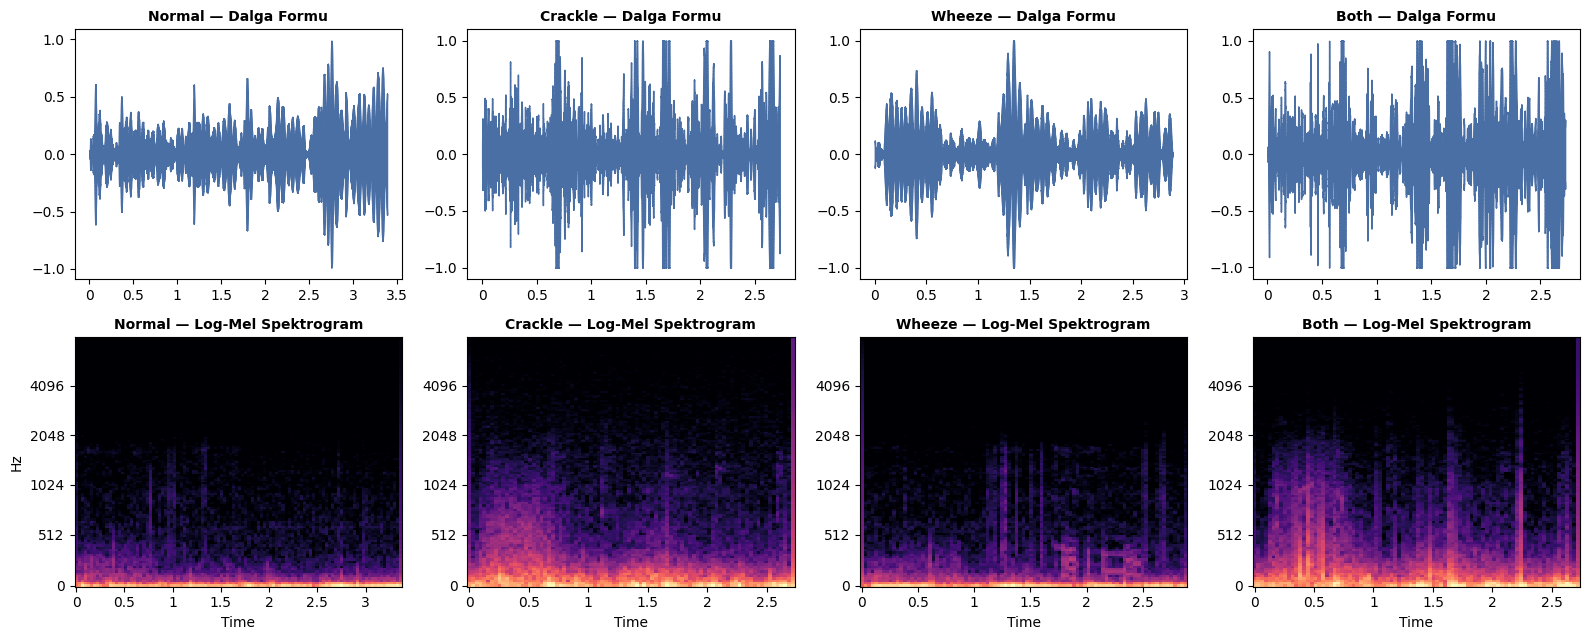

In [ ]:
# Adım 2: Keşifçi Veri Analizi (EDA) ve Yüksek Çözünürlüklü Rapor Görselleri
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

os.makedirs("assets", exist_ok=True)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"

palette = ["#a2d2ff", "#cdb4db", "#ffafcc", "#bde0fe"]
order = ["Normal", "Crackle", "Wheeze", "Both"]

# --- GRAFİK 1: Sınıf Dağılımı ve Kayıt Cihazı Analizi ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

counts = df_cycles["label"].value_counts().reindex(order)
bars = axes[0].bar(counts.index, counts.values, color=palette, edgecolor="#333333", linewidth=0.8)
axes[0].set_title("Solunum Döngüsü Sınıf Dağılımı (N = 6.898)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Döngü Sayısı")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 60, f"{h}\n(%{h/len(df_cycles)*100:.1f})",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")

ct = pd.crosstab(df_cycles["equipment"], df_cycles["label"])[order]
ct.plot(kind="bar", stacked=True, ax=axes[1], color=palette, edgecolor="#333333", linewidth=0.6)
axes[1].set_title("Stetoskop Ekipmanına Göre Sınıf Dağılımı", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kayıt Cihazı")
axes[1].set_ylabel("Döngü Sayısı")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("assets/fig1_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRAFİK 2: Solunum Döngüsü Süreleri (Duration) ---
print(f"Süre Özeti -> Ortalama: {df_cycles['duration'].mean():.2f} sn | "
      f"Medyan: {df_cycles['duration'].median():.2f} sn | "
      f"%90 Yüzdelik: {np.percentile(df_cycles['duration'], 90):.2f} sn")

plt.figure(figsize=(10, 4.2))
sns.histplot(data=df_cycles, x="duration", bins=45, kde=True, color="#a2d2ff", edgecolor="#333333")
plt.axvline(4.0, color="#e63946", linestyle="--", linewidth=2, label="Seçilen Sabit Pencere (4.0 sn)")
plt.axvline(df_cycles["duration"].median(), color="#457b9d", linestyle=":", linewidth=2,
            label=f"Medyan ({df_cycles['duration'].median():.2f} sn)")
plt.title("Solunum Döngüsü Sürelerinin Dağılımı", fontsize=12, fontweight="bold")
plt.xlabel("Süre (Saniye)")
plt.ylabel("Frekans")
plt.xlim(0, 10)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("assets/fig2_duration_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRAFİK 3: 4 Sınıf İçin Waveform & Log-Mel Spectrogram Karşılaştırması ---
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
sr_eda = 16000

for i, lbl in enumerate(order):
    sample = df_cycles[(df_cycles["label"] == lbl) & (df_cycles["duration"] >= 2.5)].iloc[0]
    y, _ = librosa.load(sample["wav_path"], sr=sr_eda,
                        offset=sample["start"], duration=min(4.0, sample["duration"]))

    # Üst satır: Waveform
    librosa.display.waveshow(y, sr=sr_eda, ax=axes[0, i], color="#4a6fa5")
    axes[0, i].set_title(f"{lbl} — Dalga Formu", fontsize=10, fontweight="bold")
    axes[0, i].set_xlabel("")
    if i > 0:
        axes[0, i].set_ylabel("")

    # Alt satır: Log-Mel Spectrogram
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr_eda, n_mels=128, n_fft=1024, hop_length=512)
    log_mel = librosa.power_to_db(mel_spec, ref=np.max)
    img = librosa.display.specshow(log_mel, sr=sr_eda, hop_length=512, x_axis="time", y_axis="mel",
                                   ax=axes[1, i], cmap="magma")
    axes[1, i].set_title(f"{lbl} — Log-Mel Spektrogram", fontsize=10, fontweight="bold")
    if i > 0:
        axes[1, i].set_ylabel("")

plt.tight_layout()
plt.savefig("assets/fig3_waveform_spectrogram.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Adım 3: Ön İşleme, Log-Mel Dönüşümü, Hasta Bazlı Bölme ve Class Weight Hesabı
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm

TARGET_SR = 16000
TARGET_DURATION = 4.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)  # 64.000 örnek
label_map = {"Normal": 0, "Crackle": 1, "Wheeze": 2, "Both": 3}

# Geçerli döngüleri filtrele (çok kısa gürültü parçalarını ele)
df_clean = df_cycles[df_cycles["duration"] >= 0.2].reset_index(drop=True)

X_list, y_list, groups_list = [], [], []

# Hız için her .wav dosyasını yalnızca 1 kez yükle
for wav_path, group_df in tqdm(df_clean.groupby("wav_path"), desc="Sesler işleniyor"):
    y_full, _ = librosa.load(wav_path, sr=TARGET_SR)

    for _, row in group_df.iterrows():
        start_idx = int(row["start"] * TARGET_SR)
        end_idx = int(row["end"] * TARGET_SR)
        clip = y_full[start_idx:end_idx]

        # Sabit uzunluğa getir (4.0 saniye)
        if len(clip) < TARGET_SAMPLES:
            clip = np.pad(clip, (0, TARGET_SAMPLES - len(clip)), mode="constant")
        else:
            clip = clip[:TARGET_SAMPLES]

        # Log-Mel Spectrogram çıkar -> (128, 126)
        mel = librosa.feature.melspectrogram(y=clip, sr=TARGET_SR, n_mels=128, n_fft=1024, hop_length=512)
        log_mel = librosa.power_to_db(mel, ref=np.max)

        # [0, 1] aralığına Min-Max normalizasyon
        log_mel_norm = (log_mel - log_mel.min()) / (log_mel.max() - log_mel.min() + 1e-8)

        # Transfer Learning (EfficientNet) uyumluluğu için 3 kanala (RGB) çoğalt -> (128, 126, 3)
        img_3ch = np.stack([log_mel_norm]*3, axis=-1).astype(np.float32)

        X_list.append(img_3ch)
        y_list.append(label_map[row["label"]])
        groups_list.append(row["patient_id"])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.int32)
groups = np.array(groups_list)

# 1. Ayrım: %70 Train, %30 Temp (Hasta bazlı)
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss1.split(X, y, groups))

X_train, y_train, groups_train = X[train_idx], y[train_idx], groups[train_idx]
X_temp, y_temp, groups_temp = X[temp_idx], y[temp_idx], groups[temp_idx]

# 2. Ayrım: %30 Temp -> %15 Validation, %15 Test (Hasta bazlı)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss2.split(X_temp, y_temp, groups_temp))

X_val, y_val = X_temp[val_idx], y_temp[val_idx]
X_test, y_test = X_temp[test_idx], y_temp[test_idx]

# RAM temizliği
del X, X_temp, X_list

# Sınıf dengesizliği için Class Weights hesapla
weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(weights)}

print("\n--- VERİ BÖLME ÖZETİ (DATA LEAKAGE KONTROLLÜ) ---")
print(f"Eğitim Seti   : {X_train.shape} | Hasta sayısı: {len(np.unique(groups_train))}")
print(f"Doğrulama Seti: {X_val.shape} | Hasta sayısı: {len(np.unique(groups_temp[val_idx]))}")
print(f"Test Seti     : {X_test.shape} | Hasta sayısı: {len(np.unique(groups_temp[test_idx]))}")
print("Sınıf Ağırlıkları (Class Weights):", {k: round(v, 3) for k, v in class_weights.items()})

Sesler işleniyor: 100%|██████████| 920/920 [01:05<00:00, 13.95it/s]



--- VERİ BÖLME ÖZETİ (DATA LEAKAGE KONTROLLÜ) ---
Eğitim Seti   : (4915, 128, 126, 3) | Hasta sayısı: 88
Doğrulama Seti: (990, 128, 126, 3) | Hasta sayısı: 19
Test Seti     : (992, 128, 126, 3) | Hasta sayısı: 19
Sınıf Ağırlıkları (Class Weights): {0: 0.473, 1: 0.929, 2: 1.876, 3: 3.614}


## 4. Model 1: Sıfırdan Özel 2D-CNN (Baseline Model)

### Mimari Seçimi ve Tasarım Gerekçesi
Log-Mel Spektrogram matrisleri `(128, 126, 3)` boyutunda 2 boyutlu zaman-frekans görüntüleri olarak temsil edildiği için temel (baseline) model olarak **4 konvolüsyon bloklu bir 2D-CNN** mimarisi tasarlanmıştır.
* **Katman Yapısı:** Her blokta sırasıyla `Conv2D` (3x3 filtreler, ReLU aktivasyonu), eğitim kararlılığını artıran `BatchNormalization` ve zaman-frekans boyutunu yarıya indiren `MaxPooling2D` kullanılmıştır (Filtre sayıları: `32 -> 64 -> 128 -> 256`).
* **Boyut İndirgeme ve Çıkış:** Parametre patlamasını ve aşırı öğrenmeyi (overfitting) önlemek amacıyla `Flatten` yerine `GlobalAveragePooling2D` ve `Dropout(0.4)` tercih edilmiştir. Çıkış katmanında 4 solunum sınıfı için `Softmax` aktivasyonu kullanılmıştır.
* **Kayıp Fonksiyonu ve Optimizasyon:** Tam sayı etiketler (`0, 1, 2, 3`) için `sparse_categorical_crossentropy`, adaptif öğrenme hızı için `Adam (lr=1e-3)` seçilmiştir. Sınıf dengesizliğini telafi etmek amacıyla eğitim sırasında `class_weight` parametresi aktif edilmiştir.
* **Eğitim Stratejisi:** Doğrulama kaybı (`val_loss`) 6 epoch boyunca iyileşmezse eğitimi durdurup en iyi ağırlıkları geri yükleyen `EarlyStopping` ve öğrenme hızını dinamik düşüren `ReduceLROnPlateau` kullanılmıştır.

In [ ]:
# Adım 4: Baseline 2D-CNN Modelinin Kurulması ve Eğitilmesi
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.random.set_seed(42)

def build_baseline_cnn(input_shape=(128, 126, 3), num_classes=4):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Blok 1
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Blok 2
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Blok 3
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Blok 4
        layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        # Sınıflandırıcı Başlık
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax")
    ], name="Baseline_2D_CNN")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

cb_baseline = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=cb_baseline,
    verbose=1
)

Model: "Baseline_2D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 63, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 31, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 31, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 15, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 15, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 42s 153ms/step - accuracy: 0.3367 - loss: 1.3818 - val_accuracy: 0.3828 - val_loss: 1.1514 - learning_rate: 0.0010
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.3723 - loss: 1.3164 - val_accuracy: 0.5465 - val_loss: 1.1846 - learning_rate: 0.0010
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3866 - loss: 1.2834 - val_accuracy: 0.3798 - val_loss: 1.4924 - learning_rate: 0.0010
Epoch 4/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.4051 - loss: 1.2523 - val_accuracy: 0.4333 - val_loss: 1.1491 - learning_rate: 0.0010
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.4307 - loss: 1.2282 - val_accuracy: 0.5323 - val_loss: 1.1601 - learning_rate: 0.0010
Epoch 6/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.4409 - loss: 1.2008 - val_accuracy: 0.5242 - val_loss: 1.2289 - learning_rate: 0.0010
Epoch 7/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.4566 - loss: 

## 5. Model 2: Transfer Learning (EfficientNet-B0)

### Mimari Seçimi ve İki Aşamalı Eğitim Yaklaşımı
Sıfırdan eğitilen CNN modelinin 126 hastadan elde edilen sınırlı sayıdaki spektrogram dokularını genelleme kapasitesini aşmak amacıyla **ImageNet ağırlıklarıyla ön eğitimli EfficientNet-B0** mimarisi seçilmiştir.
* **Giriş Ölçekleme:** `[0, 1]` aralığındaki spektrogram tensörleri, model girişindeki `Rescaling(255.0)` katmanı ile EfficientNet'in ön eğitim dağılımına uyumlu hale getirilmiştir.
* **Aşama 1 — Özellik Çıkarımı (Feature Extraction):** Omurga (backbone) ağırlıkları dondurularak yalnızca yeni eklenen sınıflandırıcı katmanlar (`GlobalAveragePooling2D -> BatchNormalization -> Dropout(0.4) -> Dense(128, ReLU) -> Dense(4, Softmax)`) 8 epoch boyunca `lr=1e-3` ile eğitilmiştir.
* **Aşama 2 — İnce Ayar (Fine-Tuning):** Omurganın en üst 30 katmanı eğitime açılarak spektral frekans örüntülerine uyum sağlaması için çok düşük öğrenme hızıyla (`lr=1e-4`) ince ayar yapılmıştır.

In [ ]:
# Adım 5: Transfer Learning (EfficientNet-B0) Kurulumu ve İki Aşamalı Eğitimi
from tensorflow.keras.applications import EfficientNetB0

def build_efficientnet_model(input_shape=(128, 126, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)
    # [0, 1] aralığındaki veriyi EfficientNet'in beklediği [0, 255] ölçeğine çevir
    x = layers.Rescaling(255.0)(inputs)

    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=x
    )
    base_model.trainable = False  # Aşama 1 için omurgayı dondur

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_TL")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

effnet_model, base_effnet = build_efficientnet_model()

print("--- AŞAMA 1: Özellik Çıkarımı (Omurga Dondurulmuş) ---")
history_eff_stage1 = effnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=32,
    class_weight=class_weights,
    verbose=1
)

print("\n--- AŞAMA 2: İnce Ayar (Üst 30 Katman Açık) ---")
base_effnet.trainable = True
for layer in base_effnet.layers[:-30]:
    layer.trainable = False

effnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cb_effnet = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history_eff_stage2 = effnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=22,
    batch_size=32,
    class_weight=class_weights,
    callbacks=cb_effnet,
    verbose=1
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
--- AŞAMA 1: Özellik Çıkarımı (Omurga Dondurulmuş) ---
Epoch 1/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 119s 480ms/step - accuracy: 0.3713 - loss: 1.7992 - val_accuracy: 0.3747 - val_loss: 1.2371
Epoch 2/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.4350 - loss: 1.3715 - val_accuracy: 0.3616 - val_loss: 1.2560
Epoch 3/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.4655 - loss: 1.2222 - val_accuracy: 0.3687 - val_loss: 1.2866
Epoch 4/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.5137 - loss: 1.1071 - val_accuracy: 0.3576 - val_loss: 1.3237
Epoch 5/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.5188 - loss: 1.0712 - val_accuracy: 0.3889 - val_loss: 1.2823
Epoch 6/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5516 - loss: 1.0130 - val_accuracy: 0.4051 - val_loss: 1.2940
Epoch 7/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5453 - loss: 0.9892 - val_accuracy: 0.4030 - val_loss: 1.

## 6. Model Değerlendirme ve Karşılaştırma

### Değerlendirme Metrikleri ve Klinik Yorumlama Yaklaşımı
Veri setinde belirgin bir sınıf dengesizliği (`Normal: %52.8`, `Both: %7.3`) bulunduğu için tek başına **Accuracy** metriği yanıltıcı olabilmektedir. Bu nedenle iki mimari aynı bağımsız hasta test seti (`X_test`) üzerinde şu metriklerle karşılaştırılmıştır:
* **Macro F1-Score & Macro Recall:** Azınlık sınıfların (`Wheeze` ve `Both`) kaçırılmama başarısını eşit ağırlıkla ölçer. Tıbbi karar destek senaryolarında patolojik bir sesi gözden kaçırmamak (False Negative oranını düşük tutmak) kritik öneme sahiptir.
* **ROC-AUC (One-vs-Rest):** Modellerin sınıflar arası olasılık ayrıştırma gücünü özetler.
* **Karmaşıklık Matrisi (Confusion Matrix):** Sınıflar arasındaki karışma örüntülerini hem örnek sayısı hem de satır bazlı yüzde olarak gösterir.

=== TEST SETİ MODEL KARŞILAŞTIRMA TABLOSU ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,ROC-AUC (OvR)
0,Baseline 2D-CNN,0.4163,0.3145,0.2973,0.2501,0.6359
1,EfficientNet-B0 (TL),0.3438,0.3483,0.3583,0.3079,0.6448



--- Baseline 2D-CNN Sınıf Bazlı Rapor ---
              precision    recall  f1-score   support

      Normal       0.81      0.52      0.63       559
     Crackle       0.21      0.64      0.32       187
      Wheeze       0.21      0.02      0.04       148
        Both       0.02      0.01      0.01        98

    accuracy                           0.42       992
   macro avg       0.31      0.30      0.25       992
weighted avg       0.53      0.42      0.42       992


--- EfficientNet-B0 (Transfer Learning) Sınıf Bazlı Rapor ---
              precision    recall  f1-score   support

      Normal       0.78      0.35      0.48       559
     Crackle       0.25      0.29      0.27       187
      Wheeze       0.19      0.30      0.23       148
        Both       0.16      0.49      0.24        98

    accuracy                           0.34       992
   macro avg       0.35      0.36      0.31       992
weighted avg       0.53      0.34      0.38       992



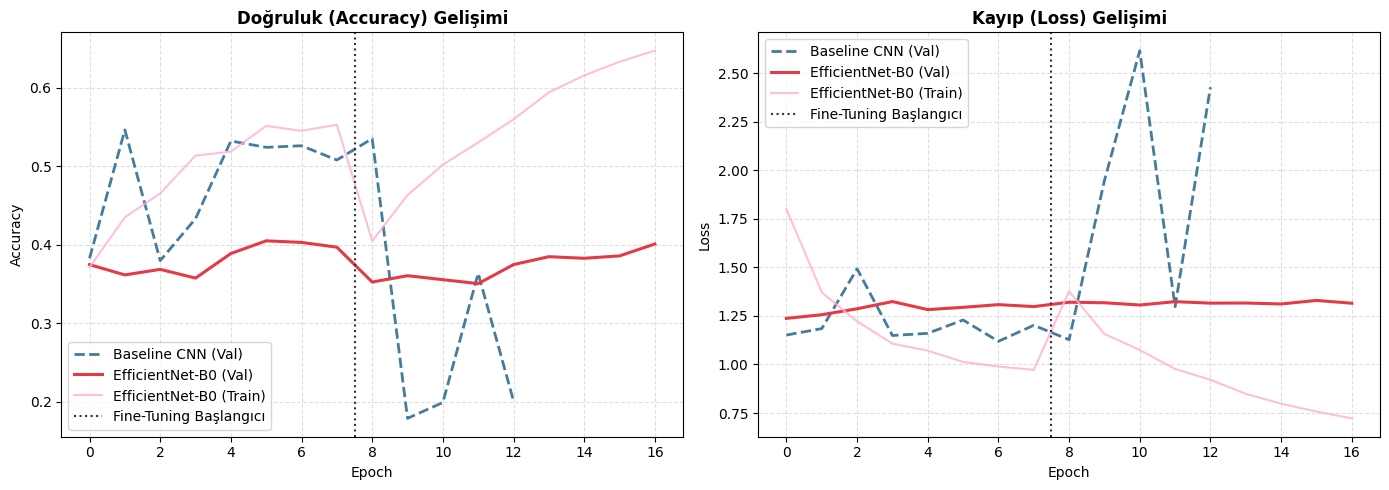

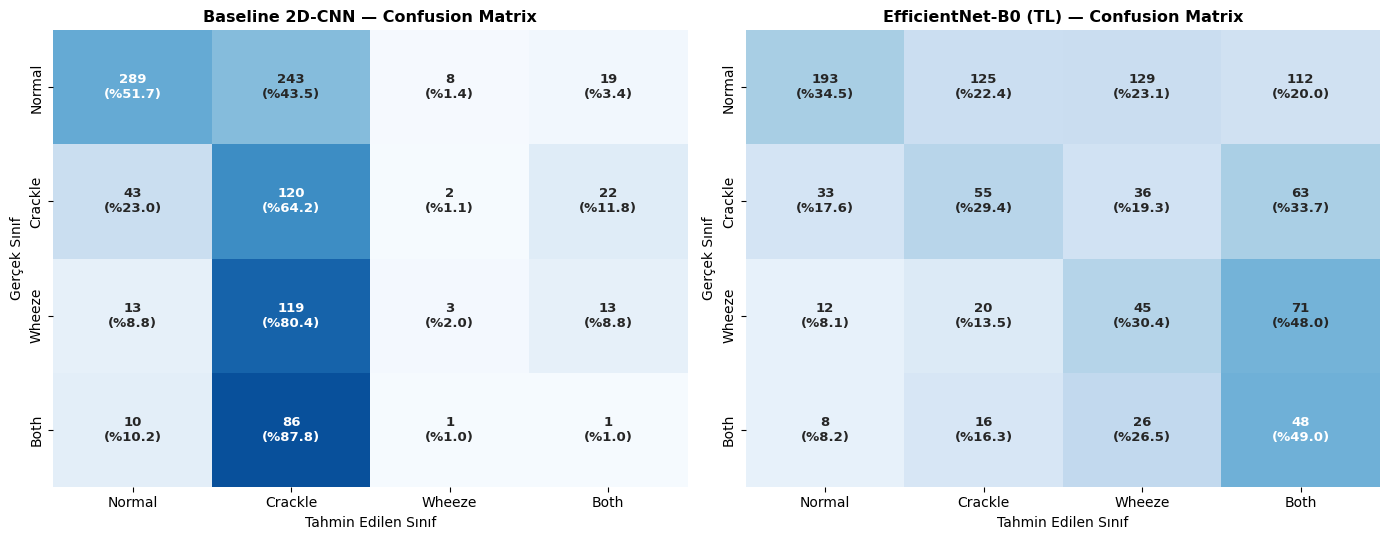

In [ ]:
# Adım 6: Test Seti Performans Karşılaştırması, Eğitim Eğrileri ve Confusion Matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

class_names = ["Normal", "Crackle", "Wheeze", "Both"]

# Test seti tahminleri
y_prob_base = baseline_model.predict(X_test, verbose=0)
y_pred_base = np.argmax(y_prob_base, axis=1)

y_prob_eff = effnet_model.predict(X_test, verbose=0)
y_pred_eff = np.argmax(y_prob_eff, axis=1)

def get_metrics(y_true, y_pred, y_prob, model_name):
    return {
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro Precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro F1-Score": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "ROC-AUC (OvR)": round(roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"), 4)
    }

df_results = pd.DataFrame([
    get_metrics(y_test, y_pred_base, y_prob_base, "Baseline 2D-CNN"),
    get_metrics(y_test, y_pred_eff, y_prob_eff, "EfficientNet-B0 (TL)")
])

print("=== TEST SETİ MODEL KARŞILAŞTIRMA TABLOSU ===")
display(df_results)

print("\n--- Baseline 2D-CNN Sınıf Bazlı Rapor ---")
print(classification_report(y_test, y_pred_base, target_names=class_names, zero_division=0))

print("\n--- EfficientNet-B0 (Transfer Learning) Sınıf Bazlı Rapor ---")
print(classification_report(y_test, y_pred_eff, target_names=class_names, zero_division=0))

# --- GRAFİK 4: Eğitim ve Doğrulama Eğrileri ---
eff_acc = history_eff_stage1.history["accuracy"] + history_eff_stage2.history["accuracy"]
eff_val_acc = history_eff_stage1.history["val_accuracy"] + history_eff_stage2.history["val_accuracy"]
eff_loss = history_eff_stage1.history["loss"] + history_eff_stage2.history["loss"]
eff_val_loss = history_eff_stage1.history["val_loss"] + history_eff_stage2.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Eğrisi
axes[0].plot(history_baseline.history["val_accuracy"], label="Baseline CNN (Val)", linestyle="--", color="#457b9d", linewidth=2)
axes[0].plot(eff_val_acc, label="EfficientNet-B0 (Val)", color="#e63946", linewidth=2.2)
axes[0].plot(eff_acc, label="EfficientNet-B0 (Train)", color="#ffafcc", alpha=0.8)
axes[0].axvline(len(history_eff_stage1.history["loss"]) - 0.5, color="#333333", linestyle=":", label="Fine-Tuning Başlangıcı")
axes[0].set_title("Doğruluk (Accuracy) Gelişimi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Loss Eğrisi
axes[1].plot(history_baseline.history["val_loss"], label="Baseline CNN (Val)", linestyle="--", color="#457b9d", linewidth=2)
axes[1].plot(eff_val_loss, label="EfficientNet-B0 (Val)", color="#e63946", linewidth=2.2)
axes[1].plot(eff_loss, label="EfficientNet-B0 (Train)", color="#ffafcc", alpha=0.8)
axes[1].axvline(len(history_eff_stage1.history["loss"]) - 0.5, color="#333333", linestyle=":", label="Fine-Tuning Başlangıcı")
axes[1].set_title("Kayıp (Loss) Gelişimi", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("assets/fig4_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRAFİK 5: Yan Yana Confusion Matrix ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_base, y_pred_eff],
    ["Baseline 2D-CNN — Confusion Matrix", "EfficientNet-B0 (TL) — Confusion Matrix"]
):
    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n(%{cm_norm[i, j]:.1f})"

    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", xticklabels=class_names,
                yticklabels=class_names, cbar=False, ax=ax, vmin=0, vmax=100,
                annot_kws={"size": 9.5, "weight": "bold"})
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Tahmin Edilen Sınıf")
    ax.set_ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig("assets/fig5_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Hata Analizi ve Geliştirme Önerileri

### Hata Kaynaklarının Akustik ve Spektral İncelemesi
Test setinde yanlış sınıflandırılan örnekler incelendiğinde hataların üç temel nedenden kaynaklandığı görülmektedir:
1. **Bileşik Sınıf Örtüşmesi (`Both` vs. `Crackle` / `Wheeze`):** Hem ral (crackle) hem hırıltı (wheeze) içeren döngülerde baskın frekans bileşeni tekli sınıflardan birini gölgeleyebilmektedir.
2. **Kayıt Gürültüsü ve Stetoskop Sürtünmesi:** Klinik ortamda alınan kayıtlardaki ani düşük frekanslı sürtünme darbeleri, spektrogramda kesikli dikey enerji çizgileri oluşturarak `Normal` döngülerin `Crackle` olarak tahmin edilmesine yol açmaktadır.
3. **Süre ve Sıfır Doldurma (Zero-Padding) Etkisi:** 1.5 saniyenin altındaki çok kısa solunum döngülerinde spektrogramın büyük kısmı sıfır dolgulu kaldığı için bilgi yoğunluğu düşmektedir.

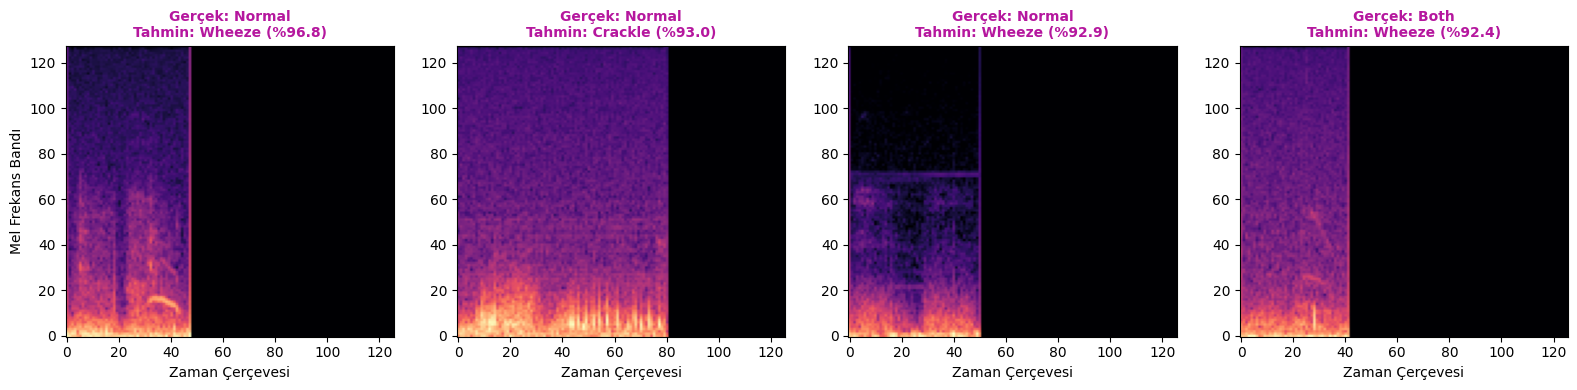

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Adım 7: En Yüksek Güven Skorlu 4 Yanlış Tahminin Spektrogram Analizi
mis_indices = np.where(y_pred_eff != y_test)[0]
confidences = np.max(y_prob_eff[mis_indices], axis=1)
top_error_idx = mis_indices[np.argsort(confidences)[::-1][:4]]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, idx in enumerate(top_error_idx):
    spec_2d = X_test[idx, :, :, 0]
    true_lbl = class_names[y_test[idx]]
    pred_lbl = class_names[y_pred_eff[idx]]
    conf = np.max(y_prob_eff[idx]) * 100

    axes[i].imshow(spec_2d, aspect="auto", origin="lower", cmap="magma")
    axes[i].set_title(f"Gerçek: {true_lbl}\nTahmin: {pred_lbl} (%{conf:.1f})",
                      fontsize=10, fontweight="bold", color="#b5179e")
    axes[i].set_xlabel("Zaman Çerçevesi")
    if i == 0:
        axes[i].set_ylabel("Mel Frekans Bandı")

plt.tight_layout()
plt.savefig("assets/fig6_error_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

# Tüm rapor görsellerini tek zip dosyası olarak indir
!zip -q -r rapor_gorselleri.zip assets/
from google.colab import files
files.download("rapor_gorselleri.zip")